**Обучение Siamese U-Net на LEVIR-CD**

Устройство: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Копирование LEVIR-CD в /content/...
train: 3144 пар изображений
val: 433 пар изображений
test: 931 пар изображений

 E0 {'id': 'E0', 'architecture': 'baseline', 'fusion': 'concat', 'loss': 'bce', 'augment': False}


E0 | 1/30:   0%|          | 0/393 [00:00<?, ?it/s]

E0, эпоха 01: loss=0.3261, val_F1=0.0000, val_IoU=0.0000


E0 | 2/30:   0%|          | 0/393 [00:00<?, ?it/s]

E0, эпоха 02: loss=0.2540, val_F1=0.2004, val_IoU=0.1114


E0 | 3/30:   0%|          | 0/393 [00:00<?, ?it/s]

... (244 outputs left out)

E4, эпоха 23: loss=0.3369, val_F1=0.6566, val_IoU=0.4887


E4 | 24/30:   0%|          | 0/393 [00:00<?, ?it/s]

E4, эпоха 24: loss=0.3325, val_F1=0.5387, val_IoU=0.3687
Early Stopping, лучшая эпоха: 17

СРАВНЕНИЕ ПО VALIDATION:


,id,architecture,loss,augment,fusion,best_epoch,val_precision,val_recall,val_f1,val_iou,val_accuracy
3,E3,unet,bce_dice,True,concat,29,0.8229,0.8492,0.8359,0.7180,0.9669
4,E4,unet,bce_dice,True,absdiff,17,0.8119,0.6308,0.7100,0.5504,0.9489
1,E1,baseline,bce_dice,False,concat,19,0.6727,0.5828,0.6245,0.4540,0.9305
0,E0,baseline,bce,False,concat,12,0.6922,0.5102,0.5874,0.4159,0.9289
2,E2,baseline,bce_dice,True,concat,20,0.6582,0.5138,0.5771,0.4056,0.9253


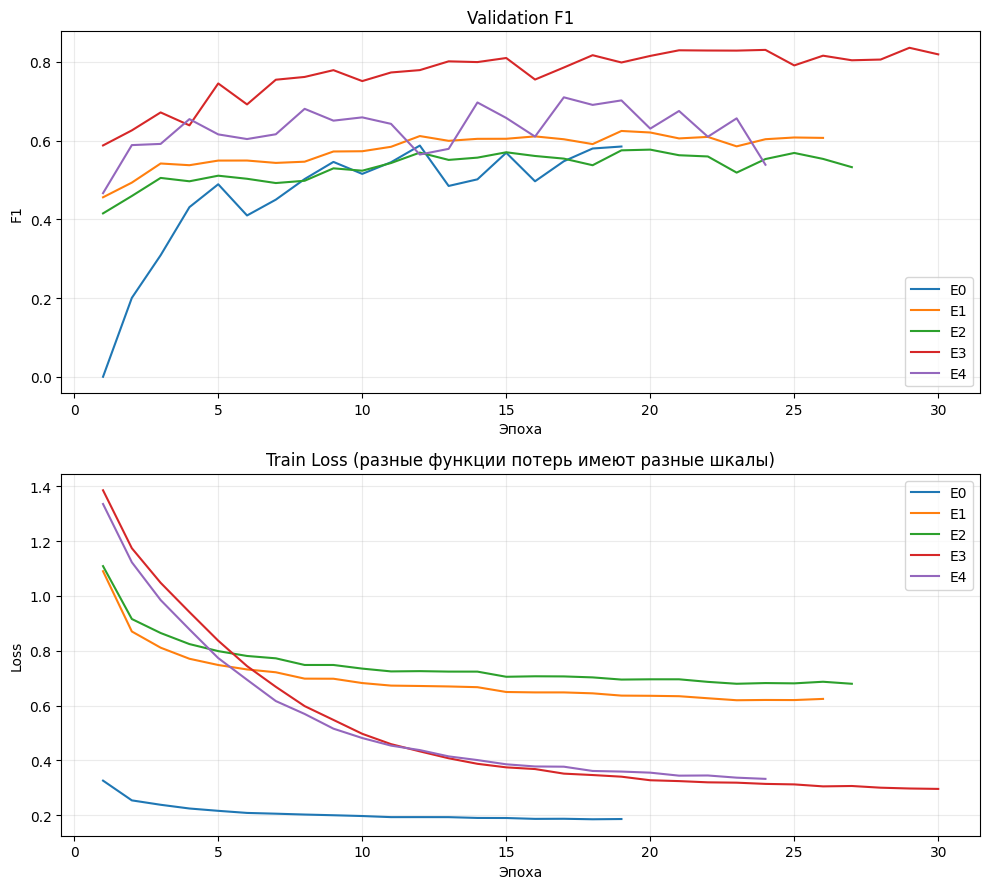

Лучшая конфигурация E3, порог=0.7

ИТОГОВЫЕ МЕТРИКИ LEVIR-CD TEST:


,precision,recall,f1,iou,accuracy,TP,FP,FN,TN
0,0.835,0.8163,0.8255,0.7029,0.9613,5581198,1103133,1256178,53073507


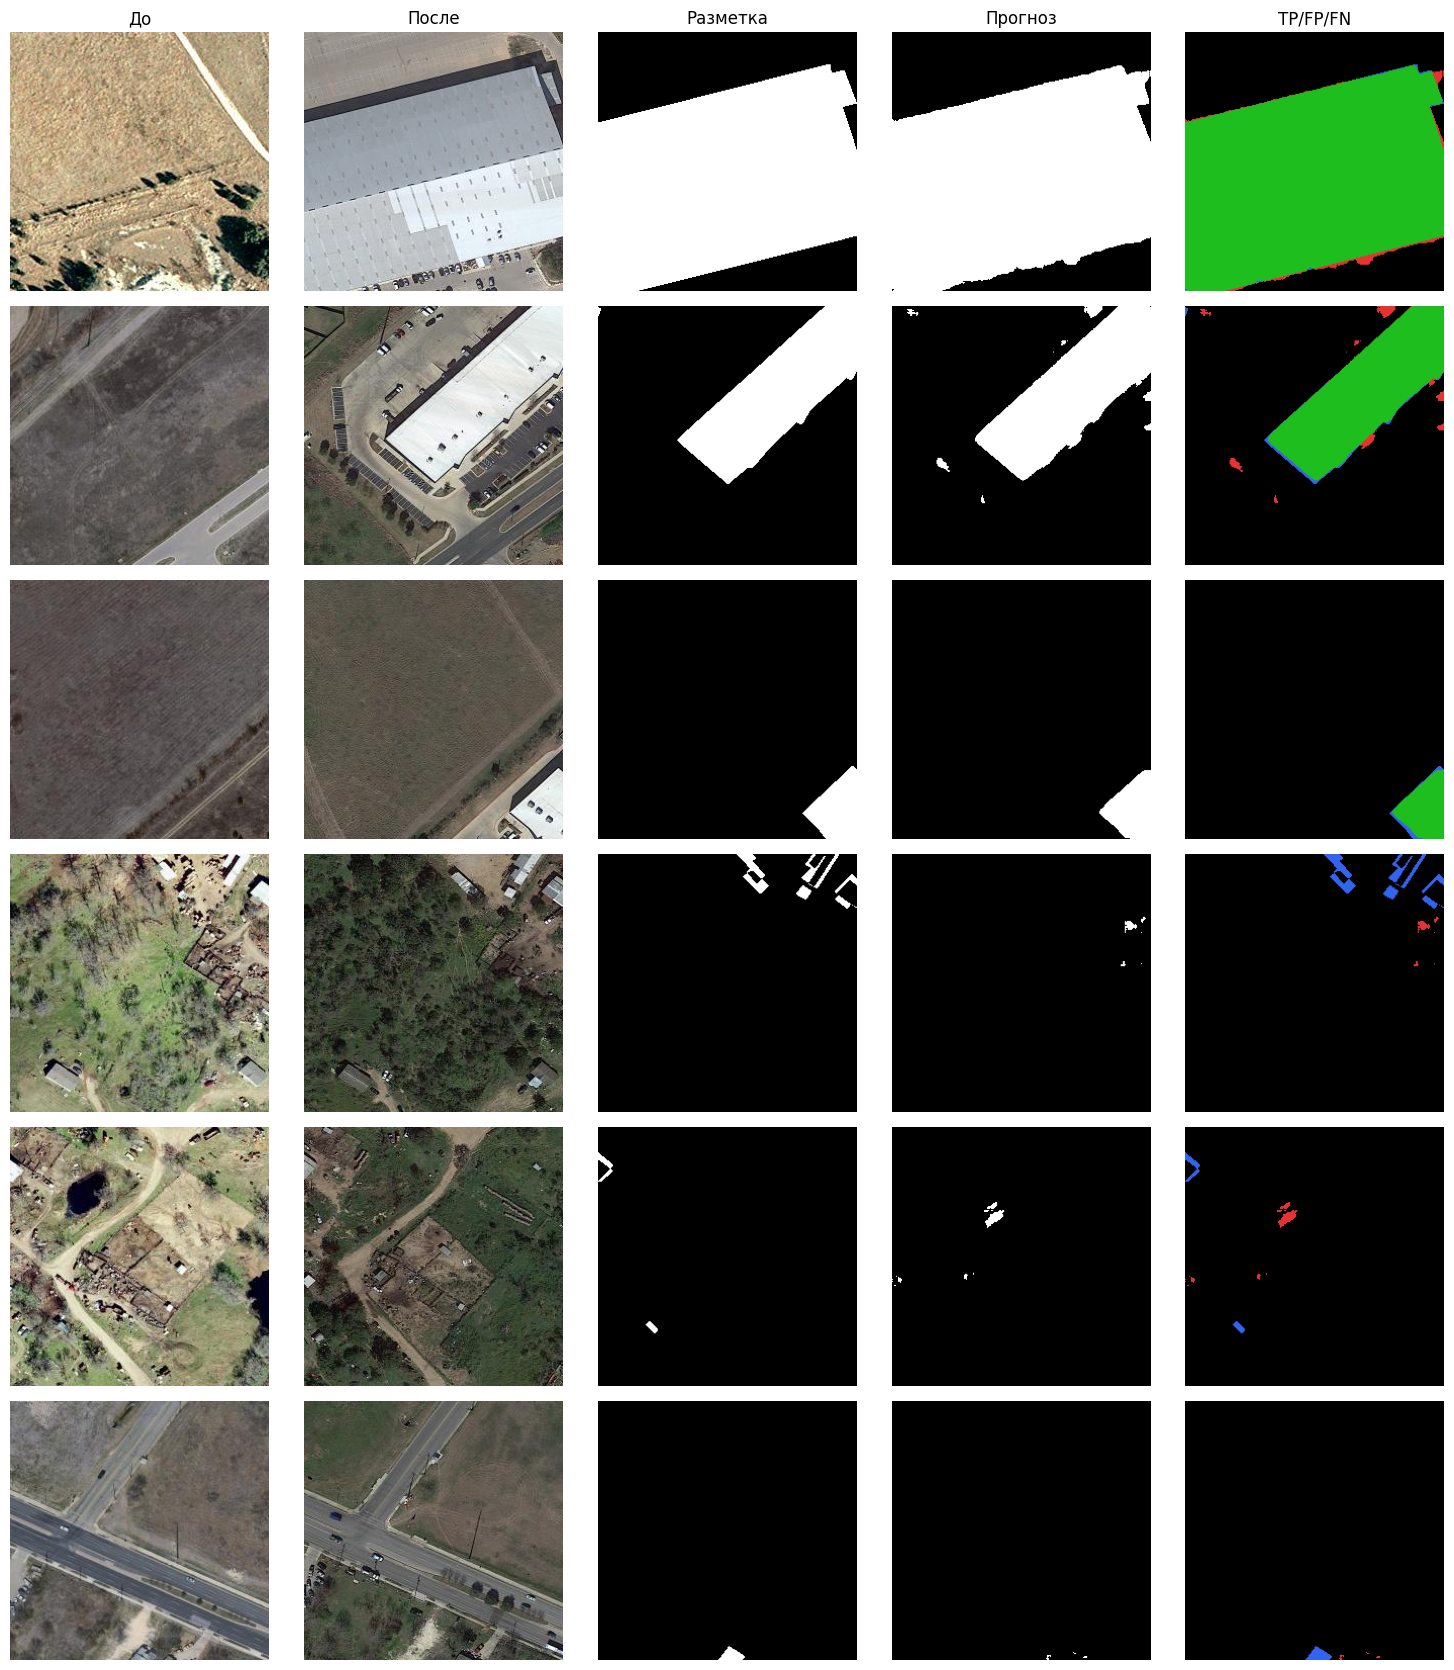


Обучение завершено. Файлы сохранены: /content/drive/MyDrive/Компьютерное зрение (Кейс LEVIR-CD)/LEVIR_experiments_results
Затем запустите ЯЧЕЙКУ №2 для внешнего тестирования на S2Looking.


In [ ]:
# Часть 3. Ячейка №1: обучение на LEVIR-CD и выбор лучшей модели
import os, re, json, random, shutil
from pathlib import Path
from contextlib import nullcontext
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from IPython.display import display
from google.colab import drive

# ---------- ПАРАМЕТРЫ ----------
SEED = 42
EPOCHS = 30               # Максимум эпох для каждого из 5 экспериментов
MIN_EPOCHS = 12            # Не останавливать раньше 12-й эпохи
PATIENCE = 7               # Early stopping по Validation F1
BATCH_SIZE = 8
LR = 1e-4
WEIGHT_DECAY = 1e-4
WORKERS = 2
PATCH_SIZE = 256

# Если датасет в другом каталоге, замените путь ниже.
ROOT = Path('/content/drive/MyDrive/Компьютерное зрение (Кейс LEVIR-CD)')
DRIVE_DATA = ROOT / 'LEVIR_processed_5K'
RESULTS = ROOT / 'LEVIR_experiments_results'

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = (DEVICE.type == 'cuda')
print('Устройство:', DEVICE)
if not AMP:
    print('ПРЕДУПРЕЖДЕНИЕ: обучение на CPU будет медленным. Включите GPU в Colab.')

drive.mount('/content/drive')
if not DRIVE_DATA.is_dir():
    raise FileNotFoundError(f'Не найден датасет: {DRIVE_DATA}. Измените DRIVE_DATA.')
RESULTS.mkdir(parents=True, exist_ok=True)

# Для ускорения обучения копируем данные с Drive на локальный диск Colab.
DATA = Path('/content/LEVIR_processed_5K')
if not DATA.is_dir():
    print('Копирование LEVIR-CD в /content/...')
    shutil.copytree(DRIVE_DATA, DATA)

# ---------- ПРОВЕРКА ИСХОДНЫХ РАЗБИЕНИЙ ----------
EXTS = {'.png', '.jpg', '.jpeg', '.tif', '.tiff'}
files_by_split = {}
sources = {}
for split in ('train', 'val', 'test'):
    base = DATA / split
    for part in ('A', 'B', 'label'):
        if not (base / part).is_dir():
            raise FileNotFoundError(base / part)
    names = sorted(p.name for p in (base / 'A').iterdir() if p.suffix.lower() in EXTS)
    if not names:
        raise ValueError(f'В {base / "A"} не найдены изображения')
    for name in names:
        if not (base / 'B' / name).is_file() or not (base / 'label' / name).is_file():
            raise FileNotFoundError(f'Отсутствует B или label для {split}/{name}')
    files_by_split[split] = names
    # Имена при вашей нарезке: имя_исходного_снимка_r0_c256.png.
    sources[split] = {re.sub(r'_r\d+_c\d+$', '', Path(x).stem) for x in names}
    print(f'{split}: {len(names)} пар изображений')
for x, y in (('train','val'), ('train','test'), ('val','test')):
    if sources[x] & sources[y]:
        raise ValueError(f'Утечка данных: общие исходные снимки в {x} и {y}')

# ---------- DATASET: одинаковые геометрические преобразования A, B и label ----------
class LEVIRDataset(Dataset):
    def __init__(self, split, augment=False):
        self.base = DATA / split
        self.names = files_by_split[split]
        self.augment = augment and split == 'train'
    def __len__(self):
        return len(self.names)
    def __getitem__(self, index):
        name = self.names[index]
        a = cv2.imread(str(self.base / 'A' / name), cv2.IMREAD_COLOR)
        b = cv2.imread(str(self.base / 'B' / name), cv2.IMREAD_COLOR)
        mask = cv2.imread(str(self.base / 'label' / name), cv2.IMREAD_GRAYSCALE)
        if a is None or b is None or mask is None:
            raise ValueError(f'Ошибка чтения {name}')
        if a.shape[:2] != b.shape[:2] or mask.shape != a.shape[:2]:
            raise ValueError(f'Различаются размеры в {name}')
        if a.shape[:2] != (PATCH_SIZE, PATCH_SIZE):
            raise ValueError(f'Ожидается патч {PATCH_SIZE}x{PATCH_SIZE}: {name}')
        a = cv2.cvtColor(a, cv2.COLOR_BGR2RGB)
        b = cv2.cvtColor(b, cv2.COLOR_BGR2RGB)
        mask = (mask > 127).astype(np.float32)
        if self.augment:
            k = random.randrange(4)
            a, b, mask = np.rot90(a,k), np.rot90(b,k), np.rot90(mask,k)
            if random.random() < 0.5:
                a, b, mask = np.fliplr(a), np.fliplr(b), np.fliplr(mask)
            if random.random() < 0.5:
                a, b, mask = np.flipud(a), np.flipud(b), np.flipud(mask)
        a = torch.from_numpy(np.ascontiguousarray(a.transpose(2,0,1))).float() / 255.0
        b = torch.from_numpy(np.ascontiguousarray(b.transpose(2,0,1))).float() / 255.0
        mask = torch.from_numpy(np.ascontiguousarray(mask[None])).float()
        return a, b, mask, name

def get_loader(split, augment=False):
    return DataLoader(
        LEVIRDataset(split, augment), batch_size=BATCH_SIZE,
        shuffle=(split=='train'), num_workers=WORKERS,
        pin_memory=AMP, persistent_workers=WORKERS>0
    )
VAL_LOADER = get_loader('val')
TEST_LOADER = get_loader('test')

# ---------- МОДЕЛЬ ИЗ ВАШЕГО БАЗОВОГО ПАЙПЛАЙНА ----------
# Отличие только в том, что Sigmoid вынесен из модели для BCEWithLogitsLoss.
class BaselineSiamese(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3,32,3,padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32,64,3,padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128,64,2,stride=2), nn.ReLU(inplace=True),
            nn.Conv2d(64,32,3,padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(32,1,1)
        )
    def forward(self, a, b):
        return self.decoder(torch.cat([self.encoder(a),self.encoder(b)],dim=1))

# ---------- ПОЛНОЦЕННАЯ SIAMESE U-NET СО SKIP CONNECTIONS ----------
class ConvBlock(nn.Module):
    def __init__(self, inp, out):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(inp,out,3,padding=1,bias=False), nn.BatchNorm2d(out), nn.ReLU(True),
            nn.Conv2d(out,out,3,padding=1,bias=False), nn.BatchNorm2d(out), nn.ReLU(True)
        )
    def forward(self, x):
        return self.net(x)

class SiameseUNet(nn.Module):
    def __init__(self, fusion='concat', base_channels=16):
        super().__init__()
        self.fusion = fusion
        c = base_channels
        factor = 2 if fusion=='concat' else 1
        self.enc1, self.enc2, self.enc3 = ConvBlock(3,c), ConvBlock(c,2*c), ConvBlock(2*c,4*c)
        self.pool = nn.MaxPool2d(2)
        self.up2 = nn.ConvTranspose2d(factor*4*c,2*c,2,stride=2)
        self.dec2 = ConvBlock(2*c+factor*2*c,2*c)
        self.up1 = nn.ConvTranspose2d(2*c,c,2,stride=2)
        self.dec1 = ConvBlock(c+factor*c,c)
        self.head = nn.Conv2d(c,1,1)
    def encode(self, x):
        f1 = self.enc1(x)
        f2 = self.enc2(self.pool(f1))
        f3 = self.enc3(self.pool(f2))
        return f1,f2,f3
    def fuse(self, x, y):
        return torch.cat([x,y],dim=1) if self.fusion=='concat' else torch.abs(x-y)
    def forward(self, a, b):
        a1,a2,a3 = self.encode(a)
        b1,b2,b3 = self.encode(b)
        x = self.dec2(torch.cat([self.up2(self.fuse(a3,b3)),self.fuse(a2,b2)],dim=1))
        x = self.dec1(torch.cat([self.up1(x),self.fuse(a1,b1)],dim=1))
        return self.head(x)

def build_model(cfg):
    if cfg['architecture']=='baseline':
        return BaselineSiamese().to(DEVICE)
    return SiameseUNet(fusion=cfg['fusion']).to(DEVICE)

class BCEDiceLoss(nn.Module):
    def __init__(self, dice=False):
        super().__init__()
        self.dice = dice
        self.bce = nn.BCEWithLogitsLoss()
    def forward(self, logits, target):
        loss = self.bce(logits,target)
        if self.dice:
            p = torch.sigmoid(logits.float())
            dice = (2*(p*target).sum()+1) / (p.sum()+target.sum()+1)
            loss = loss + 1 - dice
        return loss

# ---------- МЕТРИКИ: МИКРОУСРЕДНЕНИЕ ПО ПИКСЕЛЯМ ----------
def scores(tp,fp,fn,tn):
    def ratio(x,y): return float(x/y) if y else 0.0
    return dict(
        precision=ratio(tp,tp+fp), recall=ratio(tp,tp+fn),
        f1=ratio(2*tp,2*tp+fp+fn), iou=ratio(tp,tp+fp+fn),
        accuracy=ratio(tp+tn,tp+fp+fn+tn),
        TP=int(tp),FP=int(fp),FN=int(fn),TN=int(tn)
    )

@torch.inference_mode()
def evaluate(model, loader, threshold=0.5, per_patch=False):
    model.eval()
    tp=fp=fn=tn=0
    rows=[]
    for a,b,m,fnames in loader:
        a,b,m = a.to(DEVICE),b.to(DEVICE),m.to(DEVICE)
        with torch.autocast(device_type='cuda',enabled=AMP):
            prob = torch.sigmoid(model(a,b).float())
        pred,truth = (prob>=threshold),(m>=0.5)
        tp += int((pred & truth).sum().item())
        fp += int((pred & ~truth).sum().item())
        fn += int((~pred & truth).sum().item())
        tn += int((~pred & ~truth).sum().item())
        if per_patch:
            for i, fname in enumerate(fnames):
                p,t=pred[i],truth[i]
                pp=int((p&t).sum().item()); ff=int((p&~t).sum().item())
                nn=int((~p&t).sum().item()); tt=int((~p&~t).sum().item())
                rows.append({'file':fname,**scores(pp,ff,nn,tt)})
    return scores(tp,fp,fn,tn),pd.DataFrame(rows)

# Меняем по одному параметру между соседними экспериментами.
EXPERIMENTS = [
    dict(id='E0',architecture='baseline',fusion='concat',loss='bce',augment=False),
    dict(id='E1',architecture='baseline',fusion='concat',loss='bce_dice',augment=False),
    dict(id='E2',architecture='baseline',fusion='concat',loss='bce_dice',augment=True),
    dict(id='E3',architecture='unet',fusion='concat',loss='bce_dice',augment=True),
    dict(id='E4',architecture='unet',fusion='absdiff',loss='bce_dice',augment=True),
]

def write_json(obj,path):
    Path(path).write_text(json.dumps(obj,ensure_ascii=False,indent=2),encoding='utf-8')

def safe_save(obj,path):
    path=Path(path)
    tmp=path.with_suffix(path.suffix+'.tmp')
    torch.save(obj,tmp)
    os.replace(tmp,path)

# ---------- ОБУЧЕНИЕ С ЧЕКПОИНТАМИ (ВЫДЕРЖИВАЕТ ПЕРЕЗАПУСК COLAB) ----------
def run_experiment(cfg):
    folder=RESULTS/cfg['id']; folder.mkdir(exist_ok=True,parents=True)
    spec={**cfg,'epochs':EPOCHS,'min_epochs':MIN_EPOCHS,'patience':PATIENCE,
          'batch_size':BATCH_SIZE,'lr':LR,'weight_decay':WEIGHT_DECAY,'seed':SEED}
    spec_file=folder/'config.json'
    if spec_file.is_file() and json.loads(spec_file.read_text(encoding='utf-8')) != spec:
        raise ValueError(f'{cfg["id"]}: параметры изменились. Переименуйте папку результатов.')
    write_json(spec,spec_file)
    done=folder/'summary.json'
    if done.exists():
        print(cfg['id'],'уже завершён; читаем сохранённые результаты')
        return json.loads(done.read_text(encoding='utf-8'))

    # Единый seed для честного сравнения начальных весов.
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if AMP: torch.cuda.manual_seed_all(SEED)
    model=build_model(cfg)
    criterion=BCEDiceLoss(dice=cfg['loss']=='bce_dice')
    optimizer=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    scaler=torch.amp.GradScaler('cuda',enabled=AMP)
    train_loader=get_loader('train',augment=cfg['augment'])
    history=[]; best=-1.0; best_epoch=0; bad_epochs=0; first=1
    last=folder/'last.pt'
    if last.exists():
        state=torch.load(last,map_location=DEVICE,weights_only=False)
        model.load_state_dict(state['model'])
        optimizer.load_state_dict(state['optimizer'])
        scaler.load_state_dict(state['scaler'])
        history=state['history']; best=state['best']; best_epoch=state['best_epoch']
        bad_epochs=state['bad_epochs']; first=state['epoch']+1
        if 'random_state' in state: random.setstate(state['random_state'])
        if 'numpy_state' in state: np.random.set_state(state['numpy_state'])
        if 'torch_rng' in state: torch.set_rng_state(state['torch_rng'].cpu())
        if AMP and 'cuda_rng' in state: torch.cuda.set_rng_state_all(state['cuda_rng'])
        print(f'Возобновление {cfg["id"]} с эпохи {first}')
    for epoch in range(first,EPOCHS+1):
        model.train(); loss_total=0.0
        for a,b,mask,_ in tqdm(train_loader,desc=f'{cfg["id"]} | {epoch}/{EPOCHS}',leave=False):
            a,b,mask=a.to(DEVICE),b.to(DEVICE),mask.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda',enabled=AMP):
                loss=criterion(model(a,b),mask)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            loss_total += float(loss.item())*len(a)
        validation,_=evaluate(model,VAL_LOADER,threshold=0.5)
        train_loss=loss_total/len(train_loader.dataset)
        history.append(dict(epoch=epoch,train_loss=train_loss,**{'val_'+k:validation[k] for k in ('precision','recall','f1','iou','accuracy')}))
        if validation['f1']>best+1e-6:
            best=validation['f1']; best_epoch=epoch; bad_epochs=0
            safe_save({'model_state':model.state_dict(),'experiment':cfg,'best_epoch':best_epoch},folder/'best.pt')
        else:
            bad_epochs+=1
        pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
        safe_save(dict(model=model.state_dict(),optimizer=optimizer.state_dict(),scaler=scaler.state_dict(),
                       history=history,best=best,best_epoch=best_epoch,bad_epochs=bad_epochs,epoch=epoch,
                       random_state=random.getstate(),numpy_state=np.random.get_state(),
                       torch_rng=torch.get_rng_state(),
                       cuda_rng=torch.cuda.get_rng_state_all() if AMP else []),last)
        print(f'{cfg["id"]}, эпоха {epoch:02d}: loss={train_loss:.4f}, '
              f'val_F1={validation["f1"]:.4f}, val_IoU={validation["iou"]:.4f}')
        if epoch>=MIN_EPOCHS and bad_epochs>=PATIENCE:
            print('Early Stopping, лучшая эпоха:',best_epoch)
            break
    checkpoint=torch.load(folder/'best.pt',map_location=DEVICE,weights_only=True)
    model.load_state_dict(checkpoint['model_state'])
    val,_=evaluate(model,VAL_LOADER,threshold=0.5)
    result={**cfg,'trained_epochs':len(history),'best_epoch':best_epoch,
            'num_parameters':sum(p.numel() for p in model.parameters()),
            **{'val_'+k:val[k] for k in ('precision','recall','f1','iou','accuracy')}}
    write_json(result,done)
    return result

# ---------- ЗАПУСК E0–E4 ----------
results=[]
for cfg in EXPERIMENTS:
    print('\n'+'='*65+'\n',cfg['id'],cfg)
    results.append(run_experiment(cfg))
comparison=pd.DataFrame(results).sort_values(['val_f1','val_iou'],ascending=False)
comparison.to_csv(RESULTS/'experiment_comparison.csv',index=False)
print('\nСРАВНЕНИЕ ПО VALIDATION:')
display(comparison[['id','architecture','loss','augment','fusion','best_epoch','val_precision','val_recall','val_f1','val_iou','val_accuracy']].round(4))

# ---------- ГРАФИКИ ----------
fig,axes=plt.subplots(2,1,figsize=(10,9))
for cfg in EXPERIMENTS:
    h=pd.read_csv(RESULTS/cfg['id']/'history.csv')
    axes[0].plot(h.epoch,h.val_f1,label=cfg['id'])
    axes[1].plot(h.epoch,h.train_loss,label=cfg['id'])
axes[0].set(title='Validation F1',xlabel='Эпоха',ylabel='F1')
axes[1].set(title='Train Loss (разные функции потерь имеют разные шкалы)',xlabel='Эпоха',ylabel='Loss')
for ax in axes: ax.grid(alpha=0.25); ax.legend()
plt.tight_layout();plt.savefig(RESULTS/'training_curves.png',dpi=150);plt.show()

# ---------- ВЫБОР МОДЕЛИ И ПОРОГА ТОЛЬКО ПО VALIDATION ----------
win=comparison.iloc[0]
best_cfg=next(x for x in EXPERIMENTS if x['id']==win['id'])
model=build_model(best_cfg)
ckpt=torch.load(RESULTS/best_cfg['id']/'best.pt',map_location=DEVICE,weights_only=True)
model.load_state_dict(ckpt['model_state']);model.eval()
rows=[]
for t in np.arange(0.30,0.71,0.05):
    t=round(float(t),2)
    s,_=evaluate(model,VAL_LOADER,threshold=t)
    rows.append({'threshold':t,**{k:s[k] for k in ('f1','iou','precision','recall')}})
thresholds=pd.DataFrame(rows)
thresholds.to_csv(RESULTS/'threshold_search.csv',index=False)
thresholds['distance']=(thresholds.threshold-0.5).abs()
THRESHOLD=float(thresholds.sort_values(['f1','distance'],ascending=[False,True]).iloc[0].threshold)
print(f'Лучшая конфигурация {best_cfg["id"]}, порог={THRESHOLD}')

# ---------- ЕДИНСТВЕННАЯ ФИНАЛЬНАЯ ОЦЕНКА НА LEVIR TEST ----------
levir_test,per_patch=evaluate(model,TEST_LOADER,threshold=THRESHOLD,per_patch=True)
per_patch.to_csv(RESULTS/'levir_test_per_patch.csv',index=False)
write_json({'dataset':'LEVIR-CD','experiment':best_cfg['id'],'threshold':THRESHOLD,
            'metrics':levir_test},RESULTS/'levir_test_metrics.json')
write_json({'experiment':best_cfg,'checkpoint':f'{best_cfg["id"]}/best.pt',
            'threshold':THRESHOLD,'input_size':PATCH_SIZE,'normalization':'rgb_div_255'},
           RESULTS/'best_model.json')
print('\nИТОГОВЫЕ МЕТРИКИ LEVIR-CD TEST:')
display(pd.DataFrame([levir_test])[['precision','recall','f1','iou','accuracy','TP','FP','FN','TN']].round(4))

# ---------- ПРИМЕРЫ ПРОГНОЗОВ НА LEVIR-CD ----------
selected=pd.concat([per_patch.nlargest(3,'f1'),per_patch.nsmallest(3,'f1')]).drop_duplicates('file')
fig,axes=plt.subplots(len(selected),5,figsize=(15,len(selected)*2.8),squeeze=False)
for i,item in enumerate(selected.itertuples()):
    folder=DATA/'test'
    a=cv2.cvtColor(cv2.imread(str(folder/'A'/item.file)),cv2.COLOR_BGR2RGB)
    b=cv2.cvtColor(cv2.imread(str(folder/'B'/item.file)),cv2.COLOR_BGR2RGB)
    mask=cv2.imread(str(folder/'label'/item.file),cv2.IMREAD_GRAYSCALE)>127
    ta=torch.from_numpy(a.transpose(2,0,1).copy())[None].float().to(DEVICE)/255.0
    tb=torch.from_numpy(b.transpose(2,0,1).copy())[None].float().to(DEVICE)/255.0
    with torch.inference_mode():
        with torch.autocast(device_type='cuda',enabled=AMP):
            predicted=(torch.sigmoid(model(ta,tb).float())[0,0].cpu().numpy()>=THRESHOLD)
    errors=np.zeros((*mask.shape,3),dtype=np.uint8)
    errors[mask & predicted]=(30,190,30)    # TP зелёный
    errors[~mask & predicted]=(230,50,50)   # FP красный
    errors[mask & ~predicted]=(50,100,240)  # FN синий
    for j,arr in enumerate((a,b,mask,predicted,errors)):
        axes[i,j].imshow(arr,cmap='gray' if j in (2,3) else None)
        axes[i,j].axis('off')
        if i==0: axes[i,j].set_title(('До','После','Разметка','Прогноз','TP/FP/FN')[j])
    axes[i,0].set_ylabel(f'F1={item.f1:.3f}')
plt.tight_layout();plt.savefig(RESULTS/'levir_examples.png',dpi=150);plt.show()
print('\nОбучение завершено. Файлы сохранены:',RESULTS)
print('Затем запустите ЯЧЕЙКУ №2 для внешнего тестирования на S2Looking.')
